# Kidney compartments on Dixon (batch)

This example shows the use of the {py:func}`~miblab_dl.kidney_compartments_dixon_batch` model to 
segment renal parenchyma and renal sinus fat on Dixon data.

In [1]:
import vreg
import miblab_dl as dl
from miblab_plot import mosaic_overlay

from _data_loader import dixon_batch_case

## Download data

In [2]:
case='Dixon'
input_folder = dixon_batch_case(case)
output_folder = dl.get_cache_dir('Dixon_batch_results')

## Predict renal sinus fat masks

In [3]:
dl.kidney_compartments_dixon_batch(input_folder, output_folder)

perform_everything_on_device=True is only supported for cuda devices! Setting this to False


There are 1 cases in the source folder
I am process 0 out of 1 (max process ID is 0, we start counting with 0!)
There are 1 cases that I would like to predict



Predicting Dixon:
perform_everything_on_device: False


sending off prediction to background worker for resampling and export
done with Dixon


GPU prediction completed. Waiting for remaining segmentation exports to finish...


Segmentation export complete.


... (2 outputs left out)


Predicting Dixon:
perform_everything_on_device: False


sending off prediction to background worker for resampling and export
done with Dixon


GPU prediction completed. Waiting for remaining segmentation exports to finish...


Segmentation export complete.


## Display results

In [4]:
# Read the arrays
out_phase = vreg.read_nifti(input_folder / f'{case}_0000.nii.gz').values
label_image = vreg.read_nifti(output_folder / f'{case}.nii.gz').values

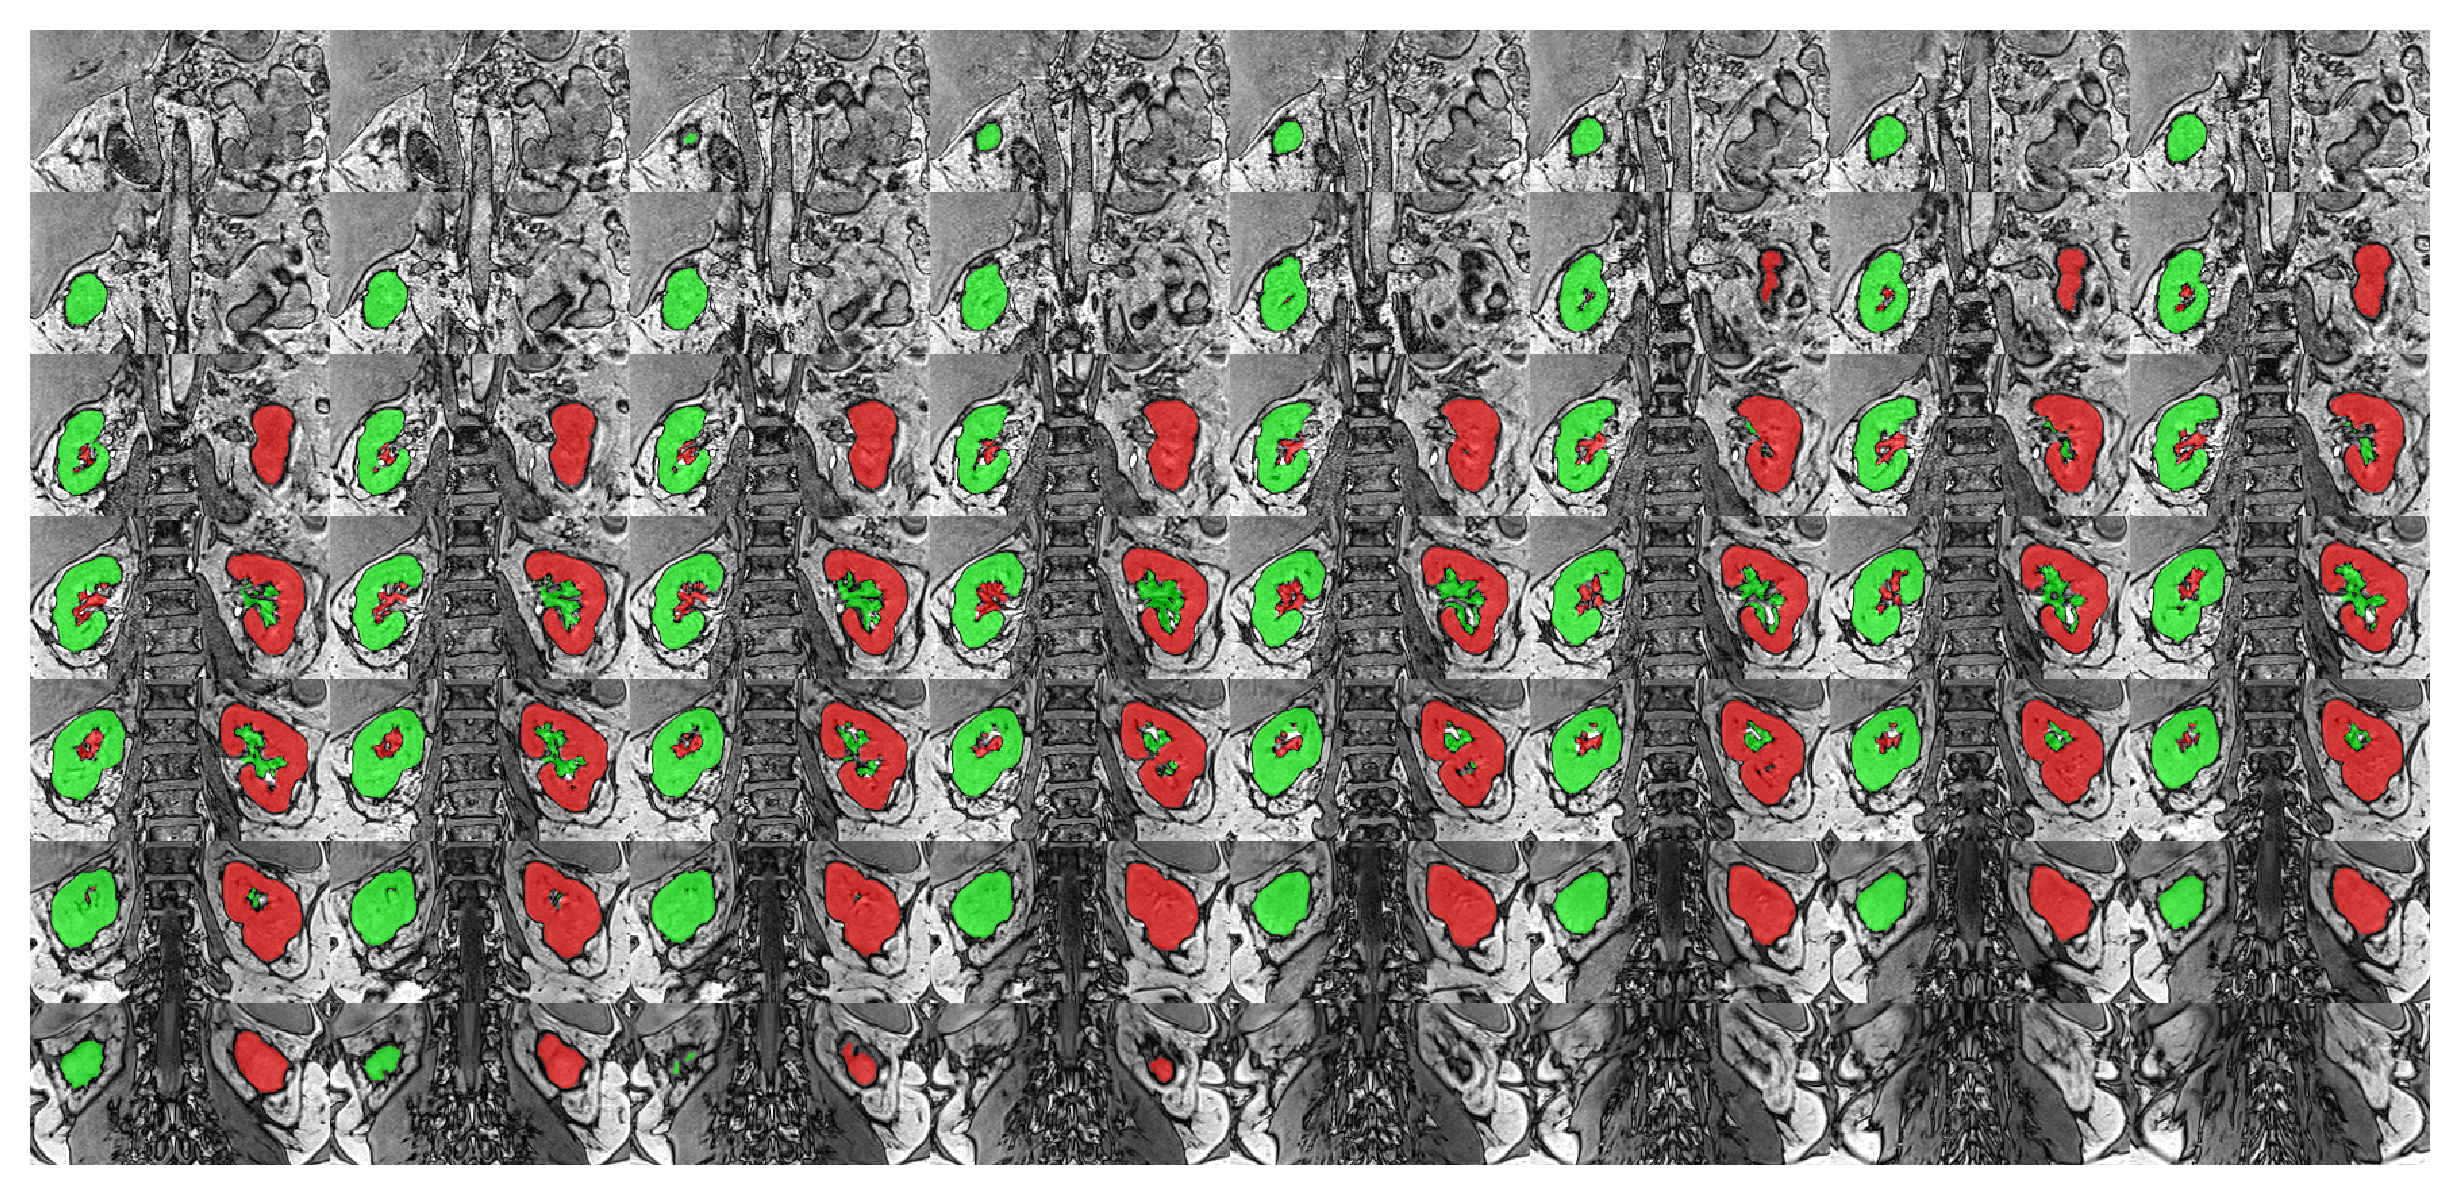

In [5]:
# Create plot
%matplotlib inline

colors = [
    [1.0, 0.0, 0.0, 0.6],   # red
    [0.0, 1.0, 0.0, 0.6],   # green
    [0.0, 1.0, 0.0, 0.6],   # green
    [1.0, 0.0, 0.0, 0.6],   # red
]
mosaic_overlay(
    out_phase,
    label_image,
    margin=[16,16,2],
    opacity=0.6,
    verbose=0,
    colors=colors
)